# 03 Random forest baseline: RGB versus 13 bands

**Purpose.** Train the classical baseline that the deep models must beat: a random forest on simple statistics of each band, once with the RGB bands and once with all 13 bands. The random forest is one of the standard scikit-learn models of the course (lecture_2_introduction_to_ML.pdf, slide 17), and building a baseline before the more complex models is step 6 of the course workflow for supervised learning (lecture_2_introduction_to_ML.pdf, slide 46).

**Functions.** `src/piece_of_crop/features.py` (`extract_rf_features`, `tune_random_forest`), `data.py` (`read_split`, `get_cache`) and `train.py` (`predictions_table`, the shared format for saved predictions).

**Reads.** `results/split.csv`, `results/band_stats.csv` and the patch cache `data/eurosat_cache.npy` (built from the GeoTIFFs on first use).

**Saves.** `results/rf_tuning.csv`, `results/rf_results.csv`, six test prediction files `results/predictions/rf_<input>_seed<n>.csv`, the figures `rf_comparison.png` and `rf_feature_importance_13band.png` in `results/figures/`, and the trained models in `models/` (not in Git; notebook 07 uses them).

## 1. Setup and shared data from notebook 02

All functions come from the installed `piece_of_crop` package. The notebook runs from `notebooks/`, so the project folder is the parent of the working folder.

In [ ]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score , classification_report,f1_score

from piece_of_crop import CLASS_NAMES, RGB_FEATURES, MS_FEATURES, read_split ,get_cache
from piece_of_crop import extract_rf_features,tune_random_forest, predictions_table

In [1]:

SEEDS=(0, 1, 2)
N_ESTIMATORS = 100 # number of trees

#paths
project_root = Path.cwd().parents[0]
data_dir = project_root / "data"/"EuroSAT_MS"
results_dir= project_root / "results"
figures_dir = results_dir/ "figures"
predictions_dir = results_dir / 'predictions'
models_dir = project_root /"models"

for folder in [results_dir, figures_dir,predictions_dir, models_dir]:
    folder.mkdir(parents=True,exist_ok = True)

split = read_split(results_dir / "split.csv" )
band_stats = pd.read_csv( results_dir / "band_stats.csv")
cache = get_cache(split, data_dir,project_root / "data" / "eurosat_cache.npy")
print("Project root:",project_root)
print("Patches per split:", split["split"].value_counts().to_dict() )
print("Cache shape :", cache.shape)

Cache already exists: /Users/estellearnander/sem5/AI/piece_of_crop/data/eurosat_cache.npy
Project root: /Users/estellearnander/sem5/AI/piece_of_crop
Patches per split: {'train': 19159, 'val': 3870, 'test': 3854, 'buffer': 117}
Cache shape: (27000, 13, 64, 64)


## 2. Features: mean and standard deviation of each band

A random forest needs one row of numbers per patch, not an image. The course notebook on image classification with classical models does exactly this: after a random forest on the raw pixels, it turns each image into features by "computing the mean and the standard deviation of the different colour values" (ImageClassificationML.pdf, page 5), and lists the mean and standard deviation of the pixel values as basic statistical features (page 11). We use the same two statistics for every band:

- **RGB:** mean and standard deviation of B02, B03 and B04, which gives 6 features.
- **13 bands:** mean and standard deviation of all 13 bands, plus the mean and standard deviation of NDVI over the patch, which gives 28 features. NDVI = (B08 - B04) / (B08 + B04) compares near-infrared and red light, which healthy plants reflect very differently.

**The asymmetry is deliberate.** NDVI needs the near-infrared band B08, which an RGB image does not have. Giving the 13-band model NDVI is part of what "having multispectral data" means, so it belongs to the comparison and is not an unfair extra. Both feature sets come from the same patches and the same training-only clipping limits from notebook 02.

**Scaling does not matter for a random forest.** The course scales features because "features with larger values/ranges can dominate the learning process" (lecture_2_introduction_to_ML.pdf, slide 49). That applies to models that combine features with weights. A tree only asks whether one feature is above a threshold, so standardising does not change its splits. We still use the clipped and standardised values so that all models start from the same preprocessing.

In [2]:
X_rgb,X_ms = extract_rf_features(cache , band_stats)

# check the shapes and that there are no nan or inf values
assert X_rgb.shape == (len(split),6)
assert X_ms.shape==(len(split), 28)
assert np.isfinite(X_rgb).all() and np.isfinite( X_ms).all()

print("RGB features:",RGB_FEATURES)
print("13-band features:", len(MS_FEATURES),"columns, the last 2 are" , MS_FEATURES[-2:])

# boolean masks for train val and test
masks = {}
for name in ["train", "val","test"]:
    masks[name] = split["split"].eq(name).to_numpy()

y = split["label"].to_numpy(dtype = int)
label_ids =np.arange(len(CLASS_NAMES))
features = {"rgb":X_rgb, "13band": X_ms}

Feature extraction: 3,008 / 27,000 images
Feature extraction: 6,016 / 27,000 images
Feature extraction: 9,024 / 27,000 images
Feature extraction: 12,032 / 27,000 images
Feature extraction: 15,040 / 27,000 images
Feature extraction: 18,048 / 27,000 images
Feature extraction: 21,056 / 27,000 images
Feature extraction: 24,000 / 27,000 images
Feature extraction: 27,000 / 27,000 images
RGB features: ['mean_B02', 'mean_B03', 'mean_B04', 'std_B02', 'std_B03', 'std_B04']
13-band features: 28 columns, the last two are ['ndvi_mean', 'ndvi_std']


## 3. Hyperparameter tuning on the validation set only

A random forest has hyperparameters that are set before training and cannot be learned from the data (lecture_2_introduction_to_ML.pdf, slide 16). The course chooses them by hyperparameter tuning, for example a grid search (slides 28 and 30), as the last step of its workflow (slide 46). We search a small grid and score every combination on the **validation** patches only, so the test patches stay unseen until the final evaluation (lecture_2_introduction_to_ML.pdf, slide 24).

The grid covers how complex each tree may become (external: scikit-learn documentation, `RandomForestClassifier`):
- `max_depth`: `None` grows each tree until its leaves are pure; 10 and 20 stop earlier.
- `min_samples_leaf`: a split must leave at least this many training patches on each side, which smooths the model.
- `max_features`: how many features each split may choose from (`"sqrt"`, the default, or half of them).

RGB and 13 bands are tuned separately, so each input gets its own best forest and neither is held back by settings chosen for the other. We select on validation macro-F1, the same metric the project reports, because it weights every class equally. The number of trees is not part of the grid, because more trees average more votes but do not make one tree more or less complex. We decided between 100 trees, the setting of the course's random forest (ImageClassificationML.pdf, page 5), and more. More trees only reduce the variation between runs, and section 5 shows whether 100 is enough: if the three seeds agree closely, adding trees could not change the comparison.

In [3]:
# grid we try for the random forest
PARAM_GRID = {
    "max_depth" : [None, 20, 10],
    "min_samples_leaf": [1,3],
    "max_features": ["sqrt",0.5]
}

best_params = {}
tuning_tables=[]
for input_type,X in features.items():
    X_train, y_train = X[masks["train"]], y[masks["train"]]
    X_val,y_val = X[masks["val"]] , y[masks["val"]]
    table, best = tune_random_forest(X_train, y_train, X_val,y_val, PARAM_GRID, seed=0,
        n_estimators = N_ESTIMATORS)
    best_params[input_type]= best
    tuning_tables.append(table.assign(input = input_type))
    print(f"{input_type}: best on validation {best}")

tuning = pd.concat(tuning_tables,ignore_index=True)
tuning.to_csv(results_dir/"rf_tuning.csv", index=False)
# top 5 setings for each input
display(tuning.groupby("input",sort=False).head(5).round(4) )

rgb: best on validation {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 3}
13band: best on validation {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 1}


,max_depth,max_features,min_samples_leaf,val_accuracy,val_macro_f1,input
0,None,0.5,3,0.7669,0.7553,rgb
1,20,0.5,1,0.7646,0.7534,rgb
2,20,sqrt,3,0.7630,0.7509,rgb
3,None,sqrt,3,0.7620,0.7495,rgb
4,None,sqrt,1,0.7620,0.7491,rgb
12,None,0.5,1,0.8912,0.8852,13band
13,None,sqrt,1,0.8904,0.8844,13band
14,20,0.5,1,0.8907,0.8843,13band
15,None,0.5,3,0.8899,0.8839,13band
16,20,sqrt,1,0.8879,0.8812,13band


**Claim.** Tuning changed the random forest only a little, so the gap between RGB and 13 bands does not depend on the settings we chose.

**Reasons.** All settings of the grid score within about one percentage point of each other on validation, while the two inputs score 13 points apart.

**Evidence.** RGB: the best combination (`max_depth=None`, `max_features=0.5`, `min_samples_leaf=3`) reaches a validation macro-F1 of 0.755, against 0.749 for the scikit-learn defaults (`max_depth=None`, `"sqrt"`, 1). 13 bands: 0.885 for the best (`max_depth=None`, `max_features=0.5`, `min_samples_leaf=1`) against 0.884 for the defaults. The full table is saved in `results/rf_tuning.csv`.

**Warrant.** Hyperparameters cannot be learned from the data and have to be searched (lecture_2_introduction_to_ML.pdf, slide 16). Because the search was done for each input separately and on validation only, neither input was held back by settings chosen for the other, and the test set played no part in the choice.

**Counterargument.** A larger grid, for example more trees or other features per split, might find a better forest. We accept this. With all twelve settings this close, a larger search would at most add a few tenths of a point, which cannot close a 13-point gap.

## 4. Train with three seeds and save the test predictions

With the chosen settings, we train one forest per input and seed. The seed changes which training patches each tree draws and which features each split may consider (external: scikit-learn documentation, `random_state`), so the spread over seeds shows how much of a difference is just chance. We report the training scores too: a large gap between training and validation shows overfitting, a model that memorises its training data (lecture_2_introduction_to_ML.pdf, slide 20).

Every test file uses the team format from `predictions_table`: `file`, `y_true`, `y_pred`, `confidence` and the probabilities `p_0` to `p_9`. Notebook 06 reads these files for the confusion matrices and the cost-weighted errors.

In [4]:

rows = [ ]
models={}

for input_type, X in features.items() :
    for seed in SEEDS:
        model =RandomForestClassifier(n_estimators=N_ESTIMATORS,random_state=seed, n_jobs = -1,
            **best_params[input_type])
        model.fit(X[masks["train"]] , y[masks["train"]])
        models[(input_type, seed)]= model
        joblib.dump(model, models_dir/ f"rf_{input_type}_seed{seed}.joblib")

        for subset,mask in masks.items():
            predicted =model.predict( X[mask])
            rows.append({"model": "RandomForest", "input":input_type, "seed": seed, "split": subset,
                "accuracy": accuracy_score(y[mask],predicted),
                "macro_f1" : f1_score(y[mask], predicted, average="macro"),
                "n_samples": int(mask.sum()),"params": str(best_params[input_type]) })
            # save the test predictions
            if subset=="test":
                out = predictions_table(split.loc[mask,"file"],y[mask],model.predict_proba(X[mask]))
                out.to_csv(predictions_dir /f"rf_{input_type}_seed{seed}.csv",index=False)
        print(f"Trained and saved :{input_type}, seed {seed}")


results_df =pd.DataFrame( rows)
results_df.to_csv(results_dir/"rf_results.csv",index= False)

Trained and saved: rgb, seed 0
Trained and saved: rgb, seed 1
Trained and saved: rgb, seed 2
Trained and saved: 13band, seed 0
Trained and saved: 13band, seed 1
Trained and saved: 13band, seed 2


## 5. Results: RGB versus 13 bands

Mean and standard deviation over the three seeds, for training, validation and test. The per-class reports show seed 0 only; the other seeds are in the prediction files.

accuracy         macro_f1        
                 mean     std     mean     std
input  split                                  
rgb    train   0.9474  0.0009   0.9460  0.0009
       val     0.7642  0.0033   0.7522  0.0038
       test    0.7002  0.0001   0.6838  0.0003
13band train   1.0000  0.0000   1.0000  0.0000
       val     0.8915  0.0004   0.8855  0.0006
       test    0.8629  0.0021   0.8562  0.0022

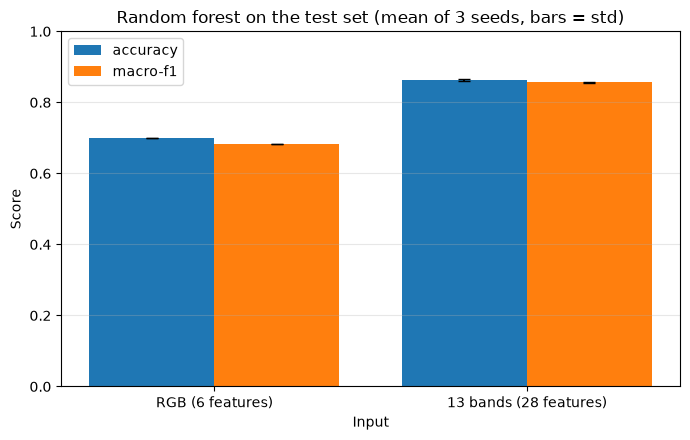


Per-class test report: rgb, seed 0
                      precision    recall  f1-score   support

          AnnualCrop       0.72      0.87      0.79       429
              Forest       0.88      0.91      0.89       429
HerbaceousVegetation       0.48      0.32      0.39       428
             Highway       0.50      0.35      0.41       358
          Industrial       0.85      0.89      0.87       357
             Pasture       0.72      0.73      0.73       286
       PermanentCrop       0.48      0.50      0.49       353
         Residential       0.64      0.81      0.72       428
               River       0.66      0.61      0.64       357
             SeaLake       0.89      0.94      0.91       429

            accuracy                           0.70      3854
           macro avg       0.68      0.69      0.68      3854
        weighted avg       0.69      0.70      0.69      3854


Per-class test report: 13band, seed 0
                      precision    recall  f1-score   

In [5]:
# mean and std over the 3 seeds
summary = results_df.groupby(["input","split"], sort=False)[["accuracy", "macro_f1"]].agg(["mean","std"])
summary = summary.round(4)
display(summary)

test_rows = results_df[results_df["split"]=="test"]
#print(test_rows.head())
test_scores = test_rows.groupby("input")[["accuracy","macro_f1"]].agg(["mean", "std"])

# bar plot of the test scores, error bars is the std
fig,ax = plt.subplots(figsize=(7,4.5))
x = np.arange(2)
acc_mean = test_scores.loc[["rgb", "13band"], ("accuracy","mean")]
acc_std = test_scores.loc[["rgb","13band"], ("accuracy", "std")]
f1_mean = test_scores.loc[["rgb", "13band"],("macro_f1", "mean")]
f1_std =test_scores.loc[["rgb","13band"], ("macro_f1","std")]
ax.bar(x-0.2, acc_mean, width = 0.4, yerr=acc_std,capsize=4, label="accuracy")
ax.bar(x + 0.2,f1_mean, width=0.4, yerr = f1_std, capsize=4, label="macro-f1")
ax.set_xticks(x, ["RGB (6 features)", "13 bands (28 features)"])
ax.set(title="Random forest on the test set (mean of 3 seeds, bars = std)", xlabel="Input",ylabel="Score",ylim=(0,1))
ax.legend()
ax.grid(axis="y" , alpha=0.3)
plt.tight_layout()
plt.savefig(figures_dir/ "rf_comparison.png", dpi=150, bbox_inches="tight")
plt.show()


# same per class report as for the cnn
pred_rgb = pd.read_csv(predictions_dir / "rf_rgb_seed0.csv")
print("\nPer class test report: rgb , seed 0")
print(classification_report(pred_rgb["y_true"],pred_rgb["y_pred"], labels = label_ids,
    target_names=list(CLASS_NAMES), zero_division=0))

pred_ms = pd.read_csv(predictions_dir/"rf_13band_seed0.csv")
print("\nPer class test report: 13band , seed 0")
print(classification_report(pred_ms["y_true"], pred_ms["y_pred"],labels=label_ids,
      target_names=list(CLASS_NAMES),zero_division=0))

**Claim.** With the same model and the same patches, the 13 bands raise the random forest's test accuracy from 70.0% to 86.3% and its macro-F1 from 0.684 to 0.856, and this gain is far larger than the variation between seeds.

**Reasons.** The extra bands describe how each surface reflects red-edge, near-infrared and short-wave infrared light, which the RGB features cannot see. Everything else is the same: the split, the clipping limits, the type of model and the tuning procedure.

**Evidence.** Test accuracy 0.700 (RGB) against 0.863 (13 bands), macro-F1 0.684 against 0.856, each the mean of three seeds with a standard deviation of at most 0.002. In the per-class reports (seed 0), all four agricultural classes improve: HerbaceousVegetation from an F1 of 0.39 to 0.74, PermanentCrop from 0.49 to 0.70, AnnualCrop from 0.79 to 0.90 and Pasture from 0.73 to 0.84. River (0.64 to 0.92) and Highway (0.41 to 0.69) also gain strongly.

**Warrant.** The test patches were never used for training or tuning, so they behave like new parcels (lecture_2_introduction_to_ML.pdf, slide 24). A difference of 16 points between inputs, against a seed spread of 0.2 points, cannot come from the random draws of the forest. Because the four agricultural classes are those an insurer checks, this answers SQ1 for the baseline: the 13-band advantage holds for the random forest.

**Counterargument 1: overfitting.** The 13-band forest scores 100% on its training patches and 89% on validation, and the RGB forest 95% against 76%. Both memorise their training data (lecture_2_introduction_to_ML.pdf, slide 20). We accept this as normal for a random forest whose trees are grown until their leaves are pure (`max_depth=None`), which validation preferred over shallower trees. What matters for the comparison is the validation and test score, and there the 13-band forest is clearly better.

**Counterargument 2: validation is higher than test.** Validation is 6.4 points above test for RGB and 2.9 points for 13 bands. Tuning on validation explains at most the 0.6 points that tuning added. The rest comes from the spatial split: validation and test are different regions of Europe, and notebook 01 showed that some classes are concentrated in certain regions (section 7). We therefore report test scores and treat the validation scores only as a tool for choosing settings. That the drop is smaller for 13 bands is consistent with the extra bands transferring better between regions, but with one validation and one test set we cannot prove it.

## 6. Which features does the 13-band forest use?

A random forest records how much each feature reduced the impurity of its splits, summed over all trees (external: scikit-learn documentation, `feature_importances_`, "the impurity-based feature importances"). We average this over the three seeds. It shows which bands the advantage of the 13-band input comes from. It measures how much the forest *used* a feature, not whether the feature is necessary: when two bands carry similar information, the importance can be shared between them.

,mean,std
std_B02,0.1299,0.0026
ndvi_std,0.0930,0.0029
mean_B11,0.0834,0.0046
mean_B8A,0.0696,0.0069
mean_B09,0.0458,0.0049
std_B04,0.0440,0.0021
std_B03,0.0412,0.0011
std_B11,0.0373,0.0005
std_B8A,0.0332,0.0008
mean_B12,0.0327,0.0011


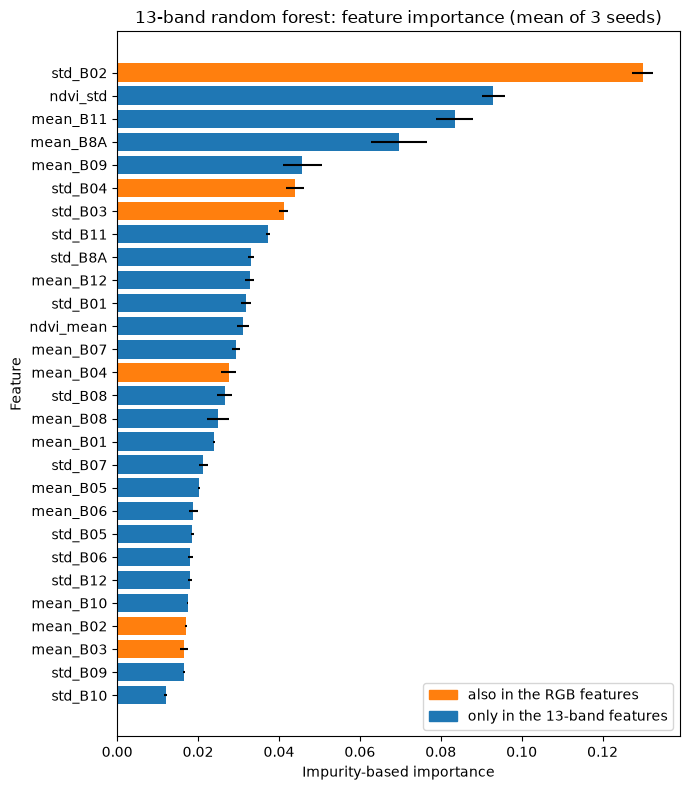

In [6]:
# feature importance for the 3 13band models
importance = {}
for seed in SEEDS:
    importance[seed] = models[("13band",seed)].feature_importances_
importance = pd.DataFrame(importance, index = MS_FEATURES)

# mean and std over the seeds, std has to be calculated before adding mean
mean_imp = importance.mean(axis=1)
std_imp = importance.std(axis = 1)
importance["mean"] = mean_imp
importance["std"]=std_imp
importance = importance.sort_values("mean")
#print(importance.head())
display(importance[["mean","std"]].sort_values("mean", ascending=False).head(10).round(4))

# orange if the feature is also in rgb, blue if its only in the 13 bands
colours = []
for name in importance.index :
    if name in RGB_FEATURES:
        colours.append("tab:orange")
    else :
        colours.append( "tab:blue")

fig, ax = plt.subplots(figsize=(7,8))
ax.barh(importance.index,importance["mean"], xerr=importance["std"], color = colours)
ax.set(title="13-band random forest: feature importance (mean of 3 seeds)",
    xlabel="Impurity-based importance",ylabel="Feature")
orange_patch = plt.Rectangle((0,0), 1, 1, color="tab:orange")
blue_patch = plt.Rectangle((0, 0),1,1, color="tab:blue")
ax.legend(handles=[orange_patch, blue_patch], labels=["also in the RGB features","only in the 13-band features"],
    loc="lower right")
plt.tight_layout()
plt.savefig(figures_dir/"rf_feature_importance_13band.png", dpi=150 , bbox_inches="tight")
plt.show()

**Claim.** The 13-band forest relies mostly on information that RGB does not have, above all the near-infrared, short-wave infrared and NDVI features. This is the source of the 13-band advantage.

**Reasons.** The bands that notebook 01 found to separate the agricultural classes are the bands the forest uses most.

**Evidence.** The 22 features that exist only in the 13-band input carry 72% of the total importance, and the 6 RGB features 28%. Among the top five, four are 13-band only: the spread of NDVI (0.093), the mean of B11 in the short-wave infrared (0.083), the mean of B8A in the near-infrared (0.070) and the mean of B09 (0.046). NDVI alone carries 12%. Notebook 01 (section 6) showed that AnnualCrop, PermanentCrop, HerbaceousVegetation and Pasture overlap in B02 to B04 and spread apart from B06 to B8A and in B12.

**Warrant.** A tree can only separate two classes on a feature where their values differ, so the features it picks most are those where the classes differ most. The match between notebook 01's spectra and the importances shows that the gain comes from spectral information and not from the larger number of features alone.

**Counterargument.** Impurity-based importance shows how much the forest used a feature, not whether it needs it. Correlated bands share importance, and the single most important feature, the spread of B02, is an RGB feature. We accept that the ranking of individual features is uncertain. The overall split of 72% against 28% is a stable finding over the three seeds (the standard deviations of the top features are below 0.007).

## Summary

- The random forest uses the mean and standard deviation of each band, plus NDVI for 13 bands, as in the course's classical image classification notebook (ImageClassificationML.pdf, page 5).
- Settings were tuned on validation only, separately for each input. Tuning changed validation macro-F1 by at most 0.6 points.
- Test results (mean of 3 seeds): RGB accuracy 0.700 and macro-F1 0.684; 13 bands accuracy 0.863 and macro-F1 0.856. The seed spread is at most 0.002.
- All four agricultural classes improve with 13 bands, HerbaceousVegetation most (F1 0.39 to 0.74). PermanentCrop remains the weakest agricultural class (0.70).
- 72% of the 13-band forest's feature importance lies in bands RGB does not have, which matches the class spectra of notebook 01.
- Both forests overfit their training data, and validation scores are higher than test scores because validation and test are different regions. All comparisons therefore use the test set.
- These predictions are the baseline that the CNN (notebook 04) and the ResNet (notebook 05) are compared with in notebook 06.